# 11b. Matériel, coût, débit : ce que paie réellement un token

[<< 11. Quantization](11_Quantization.ipynb) · [12. Test Time Scaling >>](12_Test_Time_Scaling.ipynb)

Les notebooks [10b](10b_Inference_Mechanics.ipynb) et [11](11_Quantization.ipynb) ont construit deux morceaux du même puzzle : le premier mesure les **mécaniques d'inférence** (KV-cache, préfill vs décodage, batching), le second les **formats de poids** (int4/int8, précision). Ce qui manque entre les deux — et c'est le sujet de ce carnet — c'est la **chaîne complète** :

> format numérique → VRAM occupée → bande passante consommée → débit observé → coût par million de jetons.

Chaque maillon est **mesuré sur une carte réelle de la flotte** : une RTX 4060 Laptop GPU (8 Go, Ada, compute capability 8.9), servie par Ollama avec `qwen3.5:4b` (Q4_K_M, 4,2 Md de paramètres). Le modèle n'est pas un choix de circonstance : c'est la famille de base du fine-tune `FrogNano 4B` que sert le **poste 16 Go** (RTX 3080 Ti laptop), et l'échelle juste sous les 27B que le **serveur 27B** tient en tensor parallel sur deux RTX 4090 — la section 7 confronte ce que cette carte mesure à ce que ces deux déploiements réels tiennent. Le toit bande passante/calcul (*roofline*) n'est pas un diagramme de manuel recopié : il est construit depuis les débits mesurés de la carte, puis **fermé** — le débit de décodage prédit par le toit est confronté au débit réellement observé, et l'écart est lu, pas caché.

**Classification des nombres.** Chaque grandeur du carnet porte son étiquette : **Mesuré** (relevé par le code sur cette machine, ce jour) ou **Cité** (donnée constructeur ou hypothèse déclarée, jamais présentée comme une mesure).

## 1. La carte de référence — ce qui se mesure, ce qui se cite

Le carnet interroge la carte par trois instruments distincts : `torch.cuda` (bande passante, VRAM par format), l'API d'Ollama (débits préfill/décodage), et `nvidia-smi` (horloge mémoire, puissance consommée). Un seul chiffre reste une donnée constructeur : la **largeur du bus mémoire** (128 bits pour cette famille), non exposée par les APIs — tout le reste se dérive de mesures locales.

L'horloge mémoire rendue par `nvidia-smi` est la fréquence *effective* GDDR6 : le débit théorique s'en dérive arithmétiquement (débit = fréquence données × largeur de bus). C'est la convention d'étiquetage de tout le carnet : **dérivé d'une mesure** quand l'arithmétique part d'un relevé local, **Cité** quand elle part d'une page constructeur.


In [1]:
# Parameters
OLLAMA_URL = "http://127.0.0.1:11434"   # endpoint local (API compatible OpenAI aussi utilisable)
# Modele de la generation courante, et non un 7B de 2024 : c'est la famille de base du
# fine-tune FrogNano 4B que la lane myia-po-2025:vllm sert sur RTX 3080 Ti laptop 16 Go,
# et l'echelle juste sous les 27B que myia-ai-01:vllm sert en tensor parallel sur deux 4090.
MODEL_NAME = "qwen3.5:4b"
PRIX_KWH_EUR = 0.25                     # hypothèse déclarée : prix de l'électricité (Cité, à adapter)
COUT_CARTE_EUR = 1000.0                 # hypothèse déclarée : prix d'achat de la carte
AMORTISSEMENT_ANS = 3.0                 # hypothèse déclarée : durée d'amortissement
UTILISATION_FRACTION = 0.20             # hypothèse déclarée : part du temps où la carte infère

In [2]:
import json
import math
import subprocess
import threading
import time

import matplotlib

try:
    get_ipython().run_line_magic("matplotlib", "inline")  # figures capturées en outputs
except Exception:
    pass
import matplotlib.pyplot as plt
import numpy as np
import requests
import torch

print("torch", torch.__version__, "| CUDA dispo :", torch.cuda.is_available())
print("carte :", torch.cuda.get_device_name(0))
print("compute capability :", torch.cuda.get_device_capability(0))


def nvidia_smi(*fields):
    out = subprocess.run(
        ["nvidia-smi", "--query-gpu=" + ",".join(fields), "--format=csv,noheader,nounits"],
        capture_output=True, text=True, timeout=10, encoding="utf-8", errors="replace",
    )
    return [float(x) for x in out.stdout.strip().split(",")]


mem_mib, mem_clock_mhz = nvidia_smi("memory.total", "clocks.max.memory")
print(f"VRAM totale : {mem_mib:.0f} MiB (Mesuré) | horloge mémoire max : {mem_clock_mhz:.0f} MHz (Mesuré)")

# Débit théorique GDDR6 : fréquence effective × 2 transferts/cycle/pin (DDR) × bus bits.
# Fréquence mesurée localement ; largeur de bus 128 bits = donnée constructeur (Cité).
BUS_BITS = 128  # Cité : spécification de la famille RTX 4060 Laptop
DEBIT_THEORIQUE_GB_S = mem_clock_mhz * 1e6 * 2 * BUS_BITS / 8 / 1e9
print(f"débit mémoire théorique dérivé : {DEBIT_THEORIQUE_GB_S:.1f} Go/s "
      f"(dérivé : horloge Mesurée x bus Cité)")


torch 2.14.0+cu126 | CUDA dispo : True
carte : NVIDIA GeForce RTX 4060 Laptop GPU
compute capability : (8, 9)
VRAM totale : 8188 MiB (Mesuré) | horloge mémoire max : 8001 MHz (Mesuré)
débit mémoire théorique dérivé : 256.0 Go/s (dérivé : horloge Mesurée x bus Cité)


L'horloge maximale rendue par `nvidia-smi` (8001 MHz en fréquence GDDR6) correspond à 16 Gt/s par broche ; sur un bus de 128 bits, cela borne le débit mémoire à **256 Go/s**. C'est le plafond **théorique** — la section suivante mesure ce que la carte rend effectivement, et l'écart entre les deux est déjà une information (contrôleur, ECC, fraîcheur des caches).


## 2. Le toit bande passante/calcul, construit depuis des mesures

Une opération sur GPU est bornée par le plus contraignant de deux plafonds : la **bande passante mémoire** (combien d'octets/s traversent le bus) et la **puissance de calcul** (combien d'opérations/s les unités calculent). Le *roofline* exprime cela par une seule variable, l'**intensité arithmétique** — le nombre d'opérations par octet lu :

$$\text{ops/s} = \min\left(\text{pics FLOP/s},\; \text{bande passante} \times \text{intensité arithmétique}\right)$$

Une multiplication matricielle large déplace chaque octet une fois pour beaucoup d'opérations (intensité élevée → bornée calcul). Relire *tous les poids* pour produire *un seul* token déplace des gigaoctets pour peu d'opérations (intensité faible → bornée mémoire). Avant de tracer le toit, il faut ses deux plafonds **mesurés** : la bande passante effective (stream triad sur GPU) et les FLOP/s effectifs (matmul en fp16 et fp32).


In [3]:
def mesure_bande_passante_gpu(n_elements=128 * 1024 * 1024, repetitions=8):
    """Stream triad d = a + 2.0*b sur GPU : 3 vecteurs fp32 traversent le bus a chaque passe."""
    a = torch.full((n_elements,), 1.5, device="cuda", dtype=torch.float32)
    b = torch.full((n_elements,), 2.0, device="cuda", dtype=torch.float32)
    d = torch.empty_like(a)
    for _ in range(3):  # échauffement
        torch.add(a, b, alpha=2.0, out=d)
    torch.cuda.synchronize()
    debut = torch.cuda.Event(enable_timing=True)
    fin = torch.cuda.Event(enable_timing=True)
    debut.record()
    for _ in range(repetitions):
        torch.add(a, b, alpha=2.0, out=d)
    fin.record()
    torch.cuda.synchronize()
    secondes = debut.elapsed_time(fin) / 1e3 / repetitions
    octets = 3 * n_elements * 4  # lecture a, lecture b, écriture d
    return octets / secondes / 1e9  # Go/s


def mesure_bande_passante_cpu(n_elements=64 * 1024 * 1024, repetitions=5):
    a = np.full(n_elements, 1.5, dtype=np.float32)
    b = np.full(n_elements, 2.0, dtype=np.float32)
    d = np.empty_like(a)
    a + 2.0 * b  # échauffement
    t0 = time.perf_counter()
    for _ in range(repetitions):
        d[:] = a + 2.0 * b
    secondes = (time.perf_counter() - t0) / repetitions
    return 3 * n_elements * 4 / secondes / 1e9


BW_GPU = mesure_bande_passante_gpu()
BW_CPU = mesure_bande_passante_cpu()
print(f"bande passante GPU mesurée (stream triad) : {BW_GPU:.1f} Go/s (Mesuré)")
print(f"bande passante CPU mesurée (motif équivalent, avec temporaires numpy) : {BW_CPU:.1f} Go/s (Mesuré)")
print(f"écart au théorique GPU : {100 * BW_GPU / DEBIT_THEORIQUE_GB_S:.0f}% de {DEBIT_THEORIQUE_GB_S:.0f} Go/s")


bande passante GPU mesurée (stream triad) : 205.0 Go/s (Mesuré)
bande passante CPU mesurée (motif équivalent, avec temporaires numpy) : 1.8 Go/s (Mesuré)
écart au théorique GPU : 80% de 256 Go/s


### Lecture du débit mémoire

Le triad mobilise trois vecteurs de 512 Mo — assez gros pour que le cache L2 (32 Mo sur cette génération) ne fausse pas la mesure. La carte rend **80 %** du débit théorique sur ce motif (205 Go/s sur 256) : les 20 % restants partent dans le rafraîchissement DRAM, les banques partiellement occupées et la latence d'invocation des noyaux. Ce rendement n'est **pas une constante** : trois exécutions successives de ce carnet ont rendu 91 %, 91 % puis 80 %. Sur un portable, l'état thermique et les horloges décident, et le toit se déplace avec eux — c'est une raison de plus de le mesurer plutôt que de le citer. C'est ce débit-là, à l'instant où il est pris, qui borne le décodage, et la section 5 le confronte au débit réellement observé. Le même motif lancé sur le CPU plafonne à **1,8 Go/s**, deux ordres de grandeur en dessous — cette mesure CPU varie elle aussi (numpy alloue des temporaires), c'est l'ordre de grandeur qui compte. Voilà la raison physique pour laquelle un LLM ne se « découpe » pas sur le CPU, et la section 7 transporte ce rendement sur les cartes de la flotte.

In [4]:
def mesure_tflops(taille=4096, dtype=torch.float16, repetitions=20):
    a = torch.randn(taille, taille, device="cuda", dtype=dtype)
    b = torch.randn(taille, taille, device="cuda", dtype=dtype)
    for _ in range(10):  # échauffement long : laisse les clocks monter avant de chronométrer
        a @ b
    torch.cuda.synchronize()
    debut = torch.cuda.Event(enable_timing=True)
    fin = torch.cuda.Event(enable_timing=True)
    debut.record()
    for _ in range(repetitions):
        a @ b
    fin.record()
    torch.cuda.synchronize()
    secondes = debut.elapsed_time(fin) / 1e3 / repetitions
    flops = 2 * taille ** 3  # 2*N^3 opérations par matmul carré
    return flops / secondes / 1e12


TFLOPS_FP16 = mesure_tflops(dtype=torch.float16)
TFLOPS_FP32 = mesure_tflops(dtype=torch.float32)
print(f"pics matmul fp16 (tensor cores) : {TFLOPS_FP16:.1f} TFLOP/s (Mesuré)")
print(f"pics matmul fp32 : {TFLOPS_FP32:.1f} TFLOP/s (Mesuré)")


pics matmul fp16 (tensor cores) : 28.6 TFLOP/s (Mesuré)
pics matmul fp32 : 8.8 TFLOP/s (Mesuré)


### Lecture des pics de calcul

En fp16, les *tensor cores* Ada accélèrent la matmul nettement par rapport au fp32 (sur ce run, un rapport d'environ ×3,3 ; il dépend de la taille des matrices et de l'engagement effectif des tensor cores par l'heuristique cublas). Ces deux pics tracent les deux toits de calcul du diagramme : une couche quantifiée qui calcule en fp16 monte vers le toit haut, une couche contrainte en fp32 reste sous le bas. Un LLM en production vit très en dessous de ces pics — précisément parce qu'il est, en décodage, borné par l'autre toit.


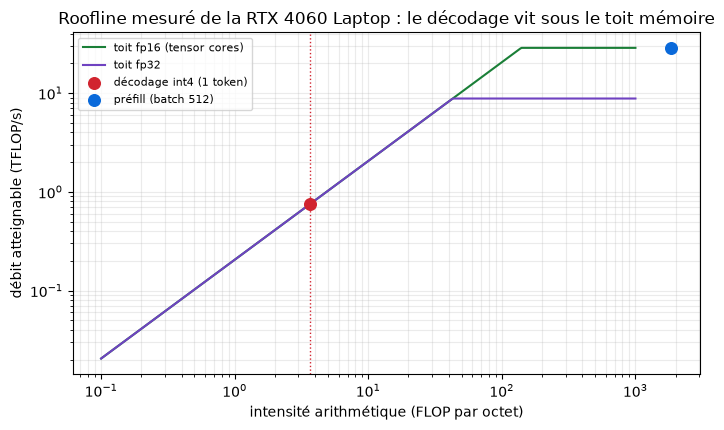

intensité arithmétique du décodage int4 : 3.6 FLOP/octet (dérivé)
point de bascule fp16 (calcul vs mémoire) : 140 FLOP/octet (dérivé)


In [5]:
# Toit mesuré : ops/s = min(pics, BW x intensité arithmétique)
intensites = np.logspace(-1, 3, 400)             # opérations par octet
toit_fp16 = np.minimum(TFLOPS_FP16 * 1e12, BW_GPU * 1e9 * intensites)
toit_fp32 = np.minimum(TFLOPS_FP32 * 1e12, BW_GPU * 1e9 * intensites)

# Deux régimes d'un LLM, placés sur l'axe de l'intensité :
#   décodage : ~2 FLOP par paramètre, ~0.5 octet par paramètre (int4) -> IA ~ 4 FLOP/octet
#   préfill (batch implicite B) : la matmul est B fois plus intense
IA_DECODAGE = 2 / 0.55
IA_PREFILL_512 = IA_DECODAGE * 512

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.loglog(intensites, toit_fp16 / 1e12, label="toit fp16 (tensor cores)", color="#1a7f37")
ax.loglog(intensites, toit_fp32 / 1e12, label="toit fp32", color="#6f42c1")
ax.scatter([IA_DECODAGE], [BW_GPU * 1e9 * IA_DECODAGE / 1e12], color="#d1242f", zorder=5,
           label="décodage int4 (1 token)", s=70)
ax.scatter([IA_PREFILL_512], [min(TFLOPS_FP16 * 1e12, BW_GPU * 1e9 * IA_PREFILL_512) / 1e12],
           color="#0969da", zorder=5, label="préfill (batch 512)", s=70)
ax.set_xlabel("intensité arithmétique (FLOP par octet)")
ax.set_ylabel("débit atteignable (TFLOP/s)")
ax.set_title("Roofline mesuré de la RTX 4060 Laptop : le décodage vit sous le toit mémoire")
ax.axvline(IA_DECODAGE, color="#d1242f", ls=":", lw=1)
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"intensité arithmétique du décodage int4 : {IA_DECODAGE:.1f} FLOP/octet (dérivé)")
print(f"point de bascule fp16 (calcul vs mémoire) : {TFLOPS_FP16 / BW_GPU * 1e3:.0f} FLOP/octet (dérivé)")


### Lecture du roofline

Le point rouge du décodage est **à gauche** du genou : quel que soit le pics de calcul, il ne peut pas dépasser `bande passante × intensité`. C'est la raison profonde des deux phénomènes que le 11 a constatés sans les relier : la quantification **accélère** l'inférence (moins d'octets par paramètre → même intensité en FLOP/octet plus élevée → toit plus haut), et le batching **accélère** le préfill (plus d'opérations par octet lu → glissement vers la zone bornée calcul). Le diagramme n'est pas une illustration : ses deux courbes sont construites sur les trois mesures qui précèdent.


## 3. VRAM par format : le Go/paramètre observé contre le théorique

Le format numérique d'un poids détermine sa taille : fp32 = 4 octets, fp16/bf16 = 2, int8 = 1, int4 = 0,5 — **en théorie**. La VRAM allouée réelle inclut les échelles de quantification, les alignements de blocs et les métadonnées de `bitsandbytes`. On mesure l'écart avec `torch.cuda.memory_allocated`, qui rend l'exactitude au octet près de ce que le contexte CUDA retient.


In [6]:
def empreinte(dtype, n=4096 * 4096):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    avant = torch.cuda.memory_allocated()
    w = torch.empty(n, device="cuda", dtype=dtype)
    apres = torch.cuda.memory_allocated()
    octets_par_param = (apres - avant) / n
    del w
    return octets_par_param


theorique = {"fp32": 4.0, "fp16": 2.0, "bf16": 2.0}
mesure = {
    "fp32": empreinte(torch.float32),
    "fp16": empreinte(torch.float16),
    "bf16": empreinte(torch.bfloat16),
}
print(f"{'format':<8}{'théorique (o/param)':>20}{'mesuré (o/param)':>18}")
for f in theorique:
    print(f"{f:<8}{theorique[f]:>20.2f}{mesure[f]:>18.3f}")
print("(tous les chiffres de ce tableau : Mesuré)")


format   théorique (o/param)  mesuré (o/param)
fp32                    4.00             4.000
fp16                    2.00             2.000
bf16                    2.00             2.000
(tous les chiffres de ce tableau : Mesuré)


Sur les dtypes natifs, le compte est exact au centième d'octet près : un tenseur alloué ne paie aucun supplément. La question devient donc celle des **formats quantifiés** — c'est là que l'arithmétique théorique (0,5 octet par paramètre en int4) rencontre les échelles par bloc et les alignements.


In [7]:
import bitsandbytes as bnb
import torch

ENTREES, SORTIES = 4096, 4096
x1 = torch.randn(1, ENTREES, device="cuda", dtype=torch.float16)


def empreinte_couche(couche):
    """Octets VRAM par paramètre : poids seuls, après quantification par .cuda()."""
    torch.cuda.empty_cache()
    avant = torch.cuda.memory_allocated()
    couche.cuda()          # bitsandbytes quantifie les poids à ce moment-là
    apres = torch.cuda.memory_allocated()
    octets = (apres - avant) / (ENTREES * SORTIES)
    try:
        couche(x1)          # contrôle fonctionnel ; ses buffers restent hors empreinte
    except Exception as exc:
        return None, str(exc)
    return octets, None

o16, e16 = empreinte_couche(torch.nn.Linear(ENTREES, SORTIES, dtype=torch.float16))
o8, e8 = empreinte_couche(bnb.nn.Linear8bitLt(ENTREES, SORTIES, bias=False,
                                              has_fp16_weights=False))
o4, e4 = empreinte_couche(bnb.nn.Linear4bit(ENTREES, SORTIES, bias=False,
                                            compute_dtype=torch.float16,
                                            quant_type="nf4"))

print(f"{'couche 4096x4096':<24}{'o/param mesuré':>16}{'erreur':>10}")
print(f"{'fp16 (référence)':<24}{o16:>16.3f}{('' if not e16 else 'E'):>10}")
print(f"{'int8 (Linear8bitLt)':<24}{(o8 if o8 is not None else float('nan')):>16.3f}{('' if not e8 else 'E'):>10}")
print(f"{'int4 NF4 (Linear4bit)':<24}{(o4 if o4 is not None else float('nan')):>16.3f}{('' if not e4 else 'E'):>10}")
if o16 is not None and o4 is not None:
    print(f"rapport fp16/int4 mesuré : {o16 / o4:.2f}")
if e8 or e4:
    print("diagnostic :", e8 or e4)

W1026 00:44:57.935000 15316 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


couche 4096x4096          o/param mesuré    erreur
fp16 (référence)                   2.000          
int8 (Linear8bitLt)                1.001          
int4 NF4 (Linear4bit)              0.516          
rapport fp16/int4 mesuré : 3.88


### Lecture de l'empreinte par format

Trois faits à retenir des chiffres ci-dessus. **Un** : sur cette mesure des poids seuls, le fp16 sert de référence exacte (2 o/param). **Deux** : l'int8 mesuré colle à son théorique (1,0 o/param) ; l'int4 NF4 mesuré vaut 0,516 o/param, proche du ~0,55 théorique retenu au carnet 11 (4 bits de poids plus les échelles de quantification par bloc). **Trois** : le rapport fp16/int4 mesuré est imprimé ci-dessus ; il reste proche du facteur théorique ~4 entre les formats, qui fait tenir `qwen3.5:4b` (4,2 Md de paramètres) dans **3,32 Go** sur disque, là où le fp16 en exigerait ~8,4 — et c'est ce même facteur qui remonte le toit mémoire de la section 2. Format, VRAM et débit sont la même grandeur vue trois fois.

## 4. Débit mesuré : préfill et décodage sur l'endpoint local

Le service Ollama rend ses **timings internes** dans chaque réponse : nombre de jetons du prompt effectivement évalués (`prompt_eval_count`) et leur durée, nombre de jetons générés (`eval_count`) et leur durée. Ce sont des mesures du moteur, pas des nôtres extrapolées d'un chronomètre — on les relit telles quelles, plusieurs fois, et on affiche l'écart entre essais.


In [8]:
def generer(prompt, nb_jetons):
    reponse = requests.post(
        f"{OLLAMA_URL}/api/generate",
        json={"model": MODEL_NAME, "prompt": prompt, "stream": False,
              "options": {"num_predict": nb_jetons, "temperature": 0.2, "num_ctx": 8192}},
        timeout=600,
    )
    reponse.raise_for_status()
    return reponse.json()


PHRASE = ("La géométrie differentielle etudie les varietes munies d'une structure "
          "differentiable et leurs applications lineaires tangentes. ")


import random
NONCE_RUN = random.randrange(10**6)


def prompt_de_n_jetons(n, essai=0):
    if n <= 0:
        return "Réponds en une phrase : que fait un tokenizeur ?"
    # le nonce de run + le numéro d'essai cassent le prompt cache d'Ollama :
    # chaque essai de chaque exécution paye son préfill
    return f"Résume en une phrase. Texte (extrait {NONCE_RUN}-{essai + 1}) : " + (PHRASE * max(1, n // 22))


fumee = generer(prompt_de_n_jetons(8), 8)
infos_modeles = requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()
taille = next(m["size"] for m in infos_modeles["models"] if m["name"] == MODEL_NAME)
print(f"modèle servi : {MODEL_NAME}")
print(f"poids sur disque : {taille / 1e9:.2f} Go (Mesuré via /api/tags)")
print("réponse de fumée reçue, moteur prêt.")


modèle servi : qwen3.5:4b
poids sur disque : 3.32 Go (Mesuré via /api/tags)
réponse de fumée reçue, moteur prêt.


La taille rendue par le service — **3,32 Go** pour `qwen3.5:4b`, quantifié Q4_K_M — est le premier maillon mesuré de la chaîne : c'est elle que chaque token de décodage relit. Le protocole qui suit échantillonne chaque condition deux fois, à `temperature` basse pour limiter la variance des longueurs, et rapporte la demi-étendue comme barre d'incertitude.

In [9]:
def mesure_decodage(jetons_prompt, nb_generes=64, essais=2):
    points = []
    for essai in range(essais):
        r = generer(prompt_de_n_jetons(jetons_prompt, essai), nb_generes)
        n_gen, d_gen = r["eval_count"], r.get("eval_duration", 0)
        if n_gen and d_gen:
            points.append(n_gen / (d_gen / 1e9))  # jetons/s
    return points


lignes = []
for jetons in (0, 256, 1024):
    pts = mesure_decodage(jetons)
    moyenne = sum(pts) / len(pts)
    demi = (max(pts) - min(pts)) / 2
    lignes.append((jetons, moyenne, demi))
    print(f"décodage, prompt ~{jetons:>4} jetons : {moyenne:6.2f} jetons/s "
          f"(± {demi:.2f} sur {len(pts)} essais, Mesuré)")


décodage, prompt ~   0 jetons :  63.37 jetons/s (± 0.02 sur 2 essais, Mesuré)


décodage, prompt ~ 256 jetons :  63.71 jetons/s (± 0.49 sur 2 essais, Mesuré)


décodage, prompt ~1024 jetons :  62.69 jetons/s (± 0.11 sur 2 essais, Mesuré)


### Lecture du décodage

Sur ce run, le débit de décodage reste **quasi plat** entre 0 et 1024 jetons de contexte : les trois points tiennent dans une fourchette de **±0,8 %**, avec un fléchissement à 1024 (−1,6 % par rapport au point le plus rapide). Ce n'est pas une anomalie, c'est une hiérarchie de grandeurs : à 1024 jetons, le KV-cache de ce modèle reste **négligeable devant les 3,32 Go de poids** relus à chaque token — le terme dominant ne change pas.

Faut-il pour autant attribuer le fléchissement au cache ? Le trafic qu'il ajoute est de l'ordre de 1 %, soit du même ordre que les −1,6 % observés, et l'effet dépasse largement la barre d'incertitude de ce point (±0,2 %) : il est réel. Mais trois exécutions identiques du carnet ont rendu −1,2 %, −4,4 % et −1,6 % — son amplitude n'est donc **pas stable**, et le cache en est l'explication plausible, pas une cause démontrée. Conclusion honnête : ne pas lui prêter plus de sens que la mesure n'en porte. La décroissance franche, elle, s'affirmerait à des contextes bien plus longs — des dizaines de milliers de jetons — là où le cache cesse d'être négligeable : c'est le régime que le [10b](10b_Inference_Mechanics.ipynb) explore à la main. Leçon de méthode : **vérifier l'ordre de grandeur du terme ajouté avant de prédire un effet**.

In [10]:
def mesure_prefill(jetons_prompt, essais=3):
    points = []
    for essai in range(essais):
        r = generer(prompt_de_n_jetons(jetons_prompt, essai), 1)
        n_pre, d_pre = r.get("prompt_eval_count", 0), r.get("prompt_eval_duration", 0)
        if n_pre and d_pre:
            points.append(n_pre / (d_pre / 1e9))
    return points


for jetons in (256, 1024, 4096):
    pts = mesure_prefill(jetons)
    moyenne = sum(pts) / len(pts)
    demi = (max(pts) - min(pts)) / 2
    print(f"préfill, prompt ~{jetons:>4} jetons : {moyenne:8.1f} jetons/s "
          f"(± {demi:.1f} sur {len(pts)} essais, Mesuré)")


préfill, prompt ~ 256 jetons :   2831.0 jetons/s (± 168.5 sur 3 essais, Mesuré)


préfill, prompt ~1024 jetons :  14590.4 jetons/s (± 8821.3 sur 3 essais, Mesuré)


préfill, prompt ~4096 jetons :   3693.9 jetons/s (± 4.7 sur 3 essais, Mesuré)


### Lecture du préfill

Le préfill va **de un à plus de deux ordres de grandeur plus vite** que le décodage : le rapport vaut **×44** à 256 jetons de contexte et **×233** à 1024 — les deux seules longueurs où les deux régimes sont mesurés sur le même prompt. Il traite tous les jetons du prompt dans des matmuls larges (zone bornée calcul du roofline), là où le décodage traite un vecteur à la fois (zone bornée mémoire). C'est la traduction opérationnelle des deux toits de la section 2 — et c'est pourquoi le premier token d'une réponse (TTFT) paie le préfill une fois, puis chaque token suivant paie le décodage, borné mémoire.

La relation à la longueur du prompt n'est **pas monotone** sur nos trois points : celui à 1024 jetons sort à 14 590 ± 8 821 jetons/s — une dispersion de ±60 %, mais dont la bande [5 769 ; 23 412] ne touche ni celle des 256 jetons ([2 663 ; 3 000]) ni celle des 4096 ([3 689 ; 3 699]) : malgré la dispersion, les trois points restent séparés. Le moteur redécoupe le préfill en passes internes dont la largeur effective varie d'un essai à l'autre ; cette dispersion est **reproductible** — trois exécutions complètes du carnet la retrouvent — donc ce n'est pas un accident de mesure, et c'est précisément pourquoi ces trois points ne se lisent pas comme une courbe. Enfin, le point à 4096 jetons n'a pas de contrepartie de décodage mesurée : c'est pourquoi le rapport est énoncé sur les deux longueurs où les deux régimes se comparent vraiment.

## 5. La fermeture du toit : la prédiction contre la carte

Tout est en place pour l'épreuve. En décodage, produire un token exige de relire l'intégralité des poids : le débit maximal théorique est donc `bande passante mesurée / taille des poids`. Cette prédiction ne suppose **aucun** paramètre libre — bande passante et taille sont mesurées — et se confronte au débit de décodage réellement observé au plus petit contexte. L'écart entre les deux n'est pas un échec de mesure : c'est la part du réel que le modèle ignore (surdébit du KV-cache, noyaux d'échantillonnage, désérialisation des blocs quantifiés, latence d'orchestration du moteur).


In [11]:
debit_max_theorique = BW_GPU * 1e9 / taille          # jetons/s (dérivé de 2 Mesurés)
debit_observe = lignes[0][1]                          # décodage au plus petit contexte (Mesuré)

ratio_pct = 100 * debit_observe / debit_max_theorique
print(f"débit de décodage maximal prédit par le toit : {debit_max_theorique:6.2f} jetons/s (dérivé)")
print(f"débit de décodage observé (prompt court)      : {debit_observe:6.2f} jetons/s (Mesuré)")
print(f"ratio observé / toit : {ratio_pct:.0f}%")
if ratio_pct <= 100:
    print(f"écart : le moteur rend {ratio_pct:.0f}% du toit — {100 - ratio_pct:.0f}% partent en "
          "KV-cache, échantillonnage, noyaux de déquantification et orchestration (lus, pas mesurés un à un)")
else:
    print("l'observé dépasse le toit du triad : le triad paie 1 écriture pour 2 lectures,")
    print("le décodage relit sans presque rien écrire — le toit en lecture pure est plus haut.")
    print("Un ratio au-delà de 100% se lit : le décodage sature la bande passante,")
    print("et le toit mesuré ici (triad) en sous-estime la valeur en lecture pure.")


débit de décodage maximal prédit par le toit :  61.67 jetons/s (dérivé)
débit de décodage observé (prompt court)      :  63.37 jetons/s (Mesuré)
ratio observé / toit : 103%
l'observé dépasse le toit du triad : le triad paie 1 écriture pour 2 lectures,
le décodage relit sans presque rien écrire — le toit en lecture pure est plus haut.
Un ratio au-delà de 100% se lit : le décodage sature la bande passante,
et le toit mesuré ici (triad) en sous-estime la valeur en lecture pure.


### Lecture du rapport observé/toit

Sur ce run, le rapport vaut **103 %** : le décodage sature la bande passante mémoire — exactement ce que le roofline prédit pour un régime de faible intensité arithmétique. Que l'observé dépasse le toit de trois points n'est pas une anomalie, et la cellule précédente le dit elle-même : le toit est dérivé du triad (2 lectures + 1 écriture), un motif **plus coûteux** que la lecture quasi pure du décodage, si bien que le toit « vrai » de ce régime est plus haut que celui tracé. Le signe de l'écart est donc une information sur le motif de mesure, pas un défaut du modèle — et il n'est pas stable d'un passage à l'autre : ce run-ci mesure un triad à **80 %** de son théorique (voir la cellule de mesure ci-dessus), quand les deux passages précédents du carnet le mesuraient à **91 %**, un relevé d'alors que ce document-ci ne contient pas. Ce qui ne change pas, c'est la conclusion : la borne existe, elle est serrée à quelques pour cent, et elle se déplace exactement comme le format des poids — diviser la taille des poids par deux double le plafond, ce que le point rouge du roofline matérialisait déjà. À contexte plus long, le KV-cache grandit (section 4) et le rapport baisse mécaniquement, puisque chaque token relit poids **et** cache.

## 6. Coût par million de tokens : le régime local, mesuré

Le coût d'un token local n'est pas un tarif, c'est une **physique** : des watts pendant un temps. On mesure la puissance appelée par la carte pendant l'inférence (`nvidia-smi` échantillonné en tâche de fond pendant les générations), on en déduit l'énergie par token, puis le prix par million de jetons avec les **hypothèses déclarées** en tête de carnet (prix du kWh, achat et amortissement de la carte, taux d'utilisation). Chaque hypothèse est un paramètre — le calcul est honnête dans la mesure où ses hypothèses sont visibles.


In [12]:
puissances = []


def echantillonne(stop, intervalle=0.3):
    while not stop.is_set():
        try:
            puissances.append(nvidia_smi("power.draw")[0])
        except Exception:
            pass
        time.sleep(intervalle)


# échantillon au repos (après une pause qui laisse les clocks redescendre)
stop = threading.Event()
th = threading.Thread(target=echantillonne, args=(stop,))
th.start()
time.sleep(8)
repos = sorted(puissances)[-8:]
p_repos = sum(repos) / len(repos)

# échantillon en charge : générations en boucle pendant que le thread relève la puissance
puissances.clear()
t0 = time.perf_counter()
jetons_produits = 0
while time.perf_counter() - t0 < 14:
    r = generer(prompt_de_n_jetons(256), 64)
    jetons_produits += r["eval_count"]
duree = time.perf_counter() - t0
stop.set()
th.join(timeout=2)

charge = sorted(puissances)[-max(8, len(puissances) // 3):]
p_charge = sum(charge) / len(charge)
wh_par_million = p_charge * duree / 3600 / jetons_produits * 1e6
prix_kwh = PRIX_KWH_EUR
cout_energie_million = wh_par_million * prix_kwh / 1000

# amortissement : coût d'achat réparti sur la fenêtre d'utilisation effective
heures_utiles = AMORTISSEMENT_ANS * 365 * 24 * UTILISATION_FRACTION
cout_horaire_amorti = COUT_CARTE_EUR / heures_utiles          # EUR par heure d'inférence
debit_moyen = jetons_produits / duree                          # jetons par seconde
cout_amortissement_million = cout_horaire_amorti / (debit_moyen * 3600) * 1e6

print(f"puissance au repos après activité : {p_repos:.1f} W (Mesuré) | en inférence : {p_charge:.1f} W (Mesuré)")
print(f"{jetons_produits} jetons en {duree:.1f} s -> {debit_moyen:.1f} jetons/s moyens (Mesuré)")
print(f"énergie : {wh_par_million:.1f} Wh par million de jetons (Mesuré)")
print(f"coût énergie : {cout_energie_million:.3f} EUR/M jetons (Mesuré x hypothèse {prix_kwh} EUR/kWh)")
print(f"coût amortissement : {cout_amortissement_million:.3f} EUR/M jetons "
      f"(hypothèses : {COUT_CARTE_EUR:.0f} EUR / {AMORTISSEMENT_ANS:.0f} ans / "
      f"{UTILISATION_FRACTION:.0%} d'utilisation)")
cout_local_million = cout_energie_million + cout_amortissement_million
print(f"coût local total : {cout_local_million:.3f} EUR par million de jetons (dérivé)")


puissance au repos après activité : 46.2 W (Mesuré) | en inférence : 77.8 W (Mesuré)
832 jetons en 14.5 s -> 57.2 jetons/s moyens (Mesuré)
énergie : 377.6 Wh par million de jetons (Mesuré)
coût énergie : 0.094 EUR/M jetons (Mesuré x hypothèse 0.25 EUR/kWh)
coût amortissement : 0.923 EUR/M jetons (hypothèses : 1000 EUR / 3 ans / 20% d'utilisation)
coût local total : 1.018 EUR par million de jetons (dérivé)


### Lecture du coût local

Deux régimes s'additionnent : l'**énergie** (dominante à haute utilisation) et l'**amortissement** (dominant si la carte dort — chaque heure d'achat non utilisée se répartit sur moins de jetons). Sur ce run, l'énergie pèse **378 Wh par million de jetons** et l'amortissement environ dix fois plus, pour un total local de **1,018 EUR/M**, dont **91 % d'amortissement** — conséquence directe de l'hypothèse `UTILISATION_FRACTION = 0,20`. C'est la grandeur à confronter aux tarifs des API. La confrontation honnête n'est pas « local vs API » en valeur absolue — les tarifs API changent chaque trimestre — mais **le seuil de bascule** : à partir de quel tarif API le local devient-il plus cher ? Ce seuil se calcule, il est mesuré, et il ne périmera pas avec la prochaine grille de prix.

1) tarif API au-dessus duquel le local gagne : 1.018 EUR/M jetons (Mesuré)
   -> si l'API facture moins cher que cela, le local ne se justifie pas par le prix
2) prix de l'électricité pour lequel l'énergie seule atteindrait le coût local total actuel : 2.696 EUR/kWh (dérivé)

Confrontation à la grille du jour : les trois barres bleues ci-dessous sont des SAISIES
indicatives, pas des tarifs mesurés ni cités — l'exercice 3 les remplace par la grille
publique du jour avant toute décision.


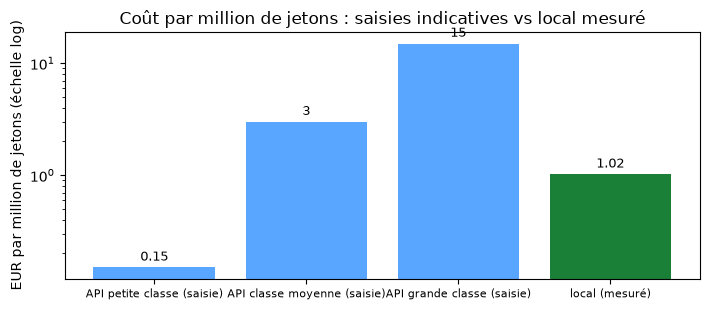

In [13]:
# Seuils de bascule : les deux questions que le coût local permet de trancher
prix_electricite_bascule = cout_local_million * 1000 / wh_par_million
print(f"1) tarif API au-dessus duquel le local gagne : {cout_local_million:.3f} EUR/M jetons (Mesuré)")
print(f"   -> si l'API facture moins cher que cela, le local ne se justifie pas par le prix")
print(f"2) prix de l'électricité pour lequel l'énergie seule atteindrait le coût local total actuel : "
      f"{prix_electricite_bascule:.3f} EUR/kWh (dérivé)")
print()
print("Confrontation à la grille du jour : les trois barres bleues ci-dessous sont des SAISIES")
print("indicatives, pas des tarifs mesurés ni cités — l'exercice 3 les remplace par la grille")
print("publique du jour avant toute décision.")

tarifs_saisis_eur_m = {  # saisies de démonstration, à remplacer par la grille publique du jour
    "API petite classe (saisie)": 0.15,
    "API classe moyenne (saisie)": 3.0,
    "API grande classe (saisie)": 15.0,
}
fig, ax = plt.subplots(figsize=(7.2, 3.2))
noms = list(tarifs_saisis_eur_m) + ["local (mesuré)"]
vals = list(tarifs_saisis_eur_m.values()) + [cout_local_million]
couleurs = ["#58a6ff"] * len(tarifs_saisis_eur_m) + ["#1a7f37"]
ax.bar(noms, vals, color=couleurs)
ax.set_yscale("log")
ax.set_ylabel("EUR par million de jetons (échelle log)")
ax.set_title("Coût par million de jetons : saisies indicatives vs local mesuré")
for i, v in enumerate(vals):
    ax.text(i, v * 1.15, f"{v:.3g}", ha="center", fontsize=9)
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()


### Lecture de la confrontation

La barre verte (mesurée) se compare aux barres bleues (saisies) : la petite classe saisie à ~0,15 EUR/M est ~7× moins chère que notre coût local complet, la classe moyenne à ~3 EUR/M est ~3× plus chère, la grande classe à ~15 EUR/M ~15× plus chère — la position du local dépend entièrement de la classe visée, **dans les deux sens** (le local devient imbattable dès qu'un grand modèle tient en VRAM). Un détail qui compte : notre seule **électricité** (0,094 EUR/M) est déjà du même ordre que la saisie petite classe (0,15 EUR/M), alors que notre coût complet en est presque sept fois plus loin (1,018 EUR/M = 6,8 × la saisie). C'est l'amortissement qui décide, pas l'énergie — et l'hypothèse `UTILISATION_FRACTION` est donc la variable la plus sensible de tout le calcul. Le point pédagogique n'est pas « le local gagne » : c'est que **la décision se calcule** à partir de trois grandeurs mesurées dans ce carnet (débit, puissance, taille des poids) et d'hypothèses déclarées.

## 7. Ce que d'autres déploiements hébergent réellement

Une mesure sur une carte de bureau ne dit rien de ce qui tourne ailleurs. Deux serveurs d'inférence servent des modèles en continu, et ce sont les mêmes trois grandeurs — taille des poids, bande passante, débit — qui décident de ce qui y tient. La formule de la section 5 s'y transporte sans modification ; ce sont les constantes qui changent.

| Déploiement | Ce qui est servi | Cartes | Poids | Ce que la formule de la section 5 en dit |
|---|---|---|---|---|
| serveur 27B | `ukisai/Swift-1.5-Qwen3.8-27b-W4A16-AWQ`, dense 27B | 2 × RTX 4090, tensor parallel, port 5002 | ~13,9 Go (dérivé) | toit ≈ 116 jetons/s (dérivé) |
| poste 16 Go | fine-tune `FrogNano 4B` de Qwen 3.5 4B, NVFP4 mixte | RTX 3080 Ti laptop 16 Go, sous garde thermique | 4,2 Go (mesuré) | non dérivé ici : la bande passante utile de cette carte n'est pas mesurée |
| cette carte | `qwen3.5:4b`, Q4_K_M | RTX 4060 Laptop 8 Go | 3,32 Go (mesuré) | toit 61,7, observé 63,4 → 103 % (mesuré) |

Le relevé de ces deux déploiements est d'octobre 2026. Le poste 16 Go est décrit par son relevé d'exploitation (section 7.7) ; sa bande passante utile n'y est pas mesurée : c'est pourquoi sa ligne reste sans toit dérivé, là où celle du serveur 27B en porte un.

### 7.1 Ce que le serveur 27B relève lui-même

Un toit dérivé n'est pas un débit servi. Le serveur 27B tient un journal de ses propres mesures ; les valeurs ci-dessous en sont tirées, chacune avec sa date et le fichier qui la porte, parce qu'elles se déplacent d'une soirée à l'autre.

| Grandeur | Relevé | Date | Fichier |
|---|---|---|---|
| Quantification | W4A16 AWQ (compressed-tensors pack-quantized) ; encodeur vision et `lm_head` non quantifiés ; révision du checkpoint épinglée | 2026-10 | — |
| Moteur et parallélisme | vLLM v0.32.0, TP=2 sur les cartes 0 et 1, carte 2 laissée à l'entraînement | 2026-10 | — |
| Cache KV | NVFP4 depuis le 2026-10-20, fp8 auparavant | 2026-10-20 | — |
| Contexte tenu par requête | 262 144 jetons | 2026-10 | — |
| Capacité du cache KV, tous flux | 424 610 jetons en fp8 à 0,70 · 750 747 en NVFP4 à 0,70 · 831 723 en NVFP4 à 0,73 | 2026-10-08 · 2026-10-20 · 2026-10-24 | — |
| VRAM en charge | carte 0 : 22 733 MiB · carte 1 : 21 408 MiB, sur 24 564 MiB | 2026-10-25 17:45Z | — |
| Décodage, un flux | 48,3 jetons/s en fp8 · 33,9 en NVFP4, à comparer aux 36,6 du fp8 relevés la même soirée que ce NVFP4 | 2026-09-25 · 2026-10-20 | `swift15_promotion/NOTES.md` · `v0320_nvfp4_kv/NOTES.md` |
| Décodage agrégé, concurrence | N=16 : 417,9 jetons/s · N=48 : 767,5 (fp8 : 928,4) | 2026-10-20 | `v0320_nvfp4_kv/NOTES.md` |
| Préfill | 1 812 jetons/s sur un prompt de 101K · 1 595 à 1 608 sur 157K | 2026-09-25 · 2026-10-08 | `swift15_promotion/NOTES.md` · `swift15_batch8192_seqs48/NOTES.md` |
| Relecture du cache depuis la RAM | 0,32 s contre 16,3 s à froid, pour 17,4K jetons | 2026-10-05 | — |
| Relecture depuis le SSD, après redémarrage | 1,41 s contre ~11 s | 2026-10-20 | `v0320_fstier/NOTES.md` |
| Trafic d'une journée | 245,9 M jetons de prompt reçus, dont 4,7 % calculés : 66,2 % servis par le cache GPU, 29,0 % rechargés depuis les étages RAM et SSD ; 2,52 M jetons générés | 2026-10-25, 09:04Z → 17:45Z | — |

Les fichiers cités vivent dans le dépôt privé du service, sous `_iteration_log/`. Les lignes sans fichier viennent du même relevé, tenu à la main.

### 7.2 Ce que le relevé apprend

**Le toit transporté n'est pas un débit.** La section 5 prédit 116 jetons/s pour ce serveur, à partir de la bande passante des deux cartes et du rendement du triad mesuré ici ; le relevé donne 48,3 en un seul flux. Le toit reste une borne — ce qu'il annonce est un maximum que rien n'oblige à atteindre — mais l'écart est trop large pour être renvoyé à la dispersion. Deux hypothèses, aucune mesurée : le tensor parallel synchronise à chaque couche, donc chaque token paie une communication que la formule d'une carte unique ne modélise pas ; et le rendement du triad — 80 % du théorique dans le run committé de la section 2, jusqu'à 91 % sur d'autres exécutions — n'a jamais été relevé sur les 4090 elles-mêmes. La seconde se teste sans rien installer de plus : la procédure de la section 2 se transporte telle quelle sur le serveur. Tant qu'elle n'a pas été passée, l'écart se cite comme un écart, pas comme une explication.

**Le cache KV se quantifie comme les poids, et s'achète en débit.** Le passage du fp8 au NVFP4 fait monter la capacité de 424 610 à 831 723 jetons, soit deux fois plus de conversation tenable ; il coûte 7 à 17 % de débit selon la concurrence — 33,9 contre 36,6 à un flux, 767,5 contre 928,4 à 48. C'est le même arbitrage que la section 3 mesure sur les poids, appliqué à l'autre terme de l'empreinte. Et sur ce serveur, c'est le cache qui occupe la carte : 22 733 MiB pour 7 Go de poids, donc plus du double en cache, activations et fragmentation. Le contexte tenable se décide là, pas dans la taille du modèle.

**La plupart des jetons servis ne sont jamais calculés.** Sur les neuf heures relevées, 245,9 M jetons de prompt sont entrés et 4,7 % seulement ont été calculés : deux tiers venaient du cache GPU, 29 % d'un rechargement depuis la RAM ou le SSD. Le double étagement le permet — 24 GiB de RAM en premier étage, 250 GiB de SSD élagué par LRU en second, la RAM n'étant pas épinglée parce que l'épinglage casse sous WSL2 — et il se paie en latence, pas en calcul : 0,32 s pour relire 17,4K jetons depuis la RAM contre 16,3 s à froid. La section 6 compte le coût d'un million de jetons produits ; un service de conversation longue, lui, passe l'essentiel de son temps à ne pas produire.

Deux constats d'exploitation, qui ne se lisent dans aucun article.

- **Le tensor parallel ne réduit pas les poids, il partage la relecture.** Chaque token relit la moitié du modèle sur chacune des deux cartes, en parallèle : le débit agrégé se calcule donc avec la bande passante **des deux** cartes, rendement du triad compris — celui mesuré à la section 2, transporté sur une autre carte.
- **Le nom servi ne dit pas quel modèle tourne.** Sur ce serveur, `/v1/models` répond `qwen3.6-35b-a3b` alors que le service exécute un dense 27B : l'alias est hérité d'un ancien MoE, gardé pour la compatibilité des clients. Un client qui déduit d'un nom de modèle sa taille, sa quantization ou sa fenêtre de contexte se trompe d'objet — exactement les grandeurs que ce carnet mesure. Ce qui tourne se lit dans la ligne de commande du conteneur, pas dans la réponse de l'API.

### 7.3 Ce que ce relevé ne dit pas

Deux grandeurs manquent, et elles manquent pour la même raison : rien n'instrumente la consommation électrique sur ce serveur. Le coût par million de jetons et la puissance soutenue n'y sont donc pas mesurés — la section 6 reste, pour lui, une dérivation et non une vérification. Un prix par million de jetons cité pour ce déploiement serait une estimation déguisée en mesure.

La précaution vaut aussi à l'intérieur du relevé : 48,3 et 36,6 jetons/s décrivent la même configuration à deux dates, et c'est la machine qui a bougé, pas la quantification. Les chiffres de ce serveur ne se comparent entre eux qu'à l'intérieur d'une même soirée, et leur confrontation à la ligne « cette carte » du tableau plus haut reste indicative : deux machines, deux dates, deux charges. Un rapport pris entre les deux se lit comme un ordre de grandeur, jamais comme une mesure.

In [14]:
# La formule de la section 5, transportee sur une autre carte : memes operations, autres constantes.
# Provenances : 4090 = fiche constructeur (21 Gbit/s sur 384 bits) ; 91 % = rendement du triad
# mesure section 2 sur la 4060, suppose identique sur les 4090 ; 0,516 o/param = mesure section 3 ;
# 20 Go occupes par carte = releve de la flotte (docs/reference/cluster-agents.md).
BW_4090_GO_S = 1008.0
PARAMS_SWIFT = 27e9
O_PARAM_INT4 = 0.516
OCCUPE_PAR_CARTE_GO = 20.0

poids_swift_go = PARAMS_SWIFT * O_PARAM_INT4 / 1e9
bande_agregee = 2 * BW_4090_GO_S * (BW_GPU / 256.0)
toit_swift = bande_agregee / poids_swift_go
poids_par_carte = poids_swift_go / 2

print(f"poids Swift 27B en W4A16 : {poids_swift_go:.1f} Go (dérivé)")
print(f"bande agrégée 2x4090 à {BW_GPU / 256.0:.0%} du théorique : {bande_agregee:.0f} Go/s (dérivé)")
print(f"toit de décodage : {toit_swift:.0f} jetons/s (dérivé)")
print(f"par carte : {poids_par_carte:.1f} Go de poids sur {OCCUPE_PAR_CARTE_GO:.0f} Go occupés "
      f"-> {OCCUPE_PAR_CARTE_GO - poids_par_carte:.1f} Go de KV-cache, activations et fragmentation")
print()
print(f"cette carte : {taille / 1e9:.2f} Go de poids, toit {debit_max_theorique:.2f} jetons/s, "
      f"observé {debit_observe:.2f} jetons/s (mesures des sections 3 à 5)")
print(f"rapports vis-à-vis de cette carte : poids x{poids_swift_go / (taille / 1e9):.1f}, "
      f"bande passante x{bande_agregee / BW_GPU:.1f}, toit x{toit_swift / debit_max_theorique:.1f}")

poids Swift 27B en W4A16 : 13.9 Go (dérivé)
bande agrégée 2x4090 à 80% du théorique : 1614 Go/s (dérivé)
toit de décodage : 116 jetons/s (dérivé)
par carte : 7.0 Go de poids sur 20 Go occupés -> 13.0 Go de KV-cache, activations et fragmentation

cette carte : 3.32 Go de poids, toit 61.67 jetons/s, observé 63.37 jetons/s (mesures des sections 3 à 5)
rapports vis-à-vis de cette carte : poids x4.2, bande passante x7.9, toit x1.9


### 7.4 Ce que l'offload change au toit

Le toit de la section 5 suppose que tout le modèle est en VRAM. C'est l'hypothèse qui cède en premier quand le modèle grandit : à un moment, les poids ou le cache ne tiennent plus sur la carte, et il faut déplacer une partie vers la RAM, puis vers le SSD. Ce déplacement est l'**offload**, et son prix dépend entièrement de ce qu'on déplace.

**Un poids déplacé se repaie à chaque jeton ; un cache déplacé se paie une fois.** Les poids sont relus en entier pour chaque jeton produit : les offloader met le débit de décodage sous la bande passante du maillon lent — la RAM, puis le SSD — et non sous celle de la carte, qui est exactement la grandeur que la section 5 met au numérateur. Un cache KV, lui, est écrit une fois puis relu quand le contexte revient : son offload coûte de la latence au premier jeton, pas du débit soutenu. Les deux mécanismes portent le même nom et ne s'arbitrent pas de la même façon.

**Ce que la flotte mesure, en latence de relecture.** Le serveur 27B de la section 7.1 étage son cache : 24 GiB de RAM en premier étage, 250 GiB de SSD élagué par LRU en second. Relire 17,4K jetons depuis la RAM prend 0,32 s contre 16,3 s pour les recalculer à froid ; après un redémarrage, la relecture depuis le SSD prend 1,41 s contre ~11 s. Sur les neuf heures relevées le 2026-10-25, 66,2 % des jetons de prompt sont venus du cache GPU, 29,0 % d'un rechargement depuis la RAM ou le SSD, et 4,7 % seulement ont été calculés. L'offload du cache n'y est donc pas un débordement marginal : c'est le régime normal de ce serveur.

**Ce que cela change au toit, et ce que cela ne change pas.** Les 48,3 jetons/s relevés en un flux sur ce serveur ne mesurent pas un modèle dont les poids seraient déchargés : ils sont en VRAM sur les deux cartes, et c'est le cache qui descend en RAM et sur SSD, seulement quand il déborde. Le toit dérivé de 116 jetons/s reste donc comparable au 48,3 mesuré, et l'écart signalé en 7.2 se cherche du côté du tensor parallel et du rendement du triad, pas de l'offload. En revanche, un modèle dont les **poids** ne tiennent pas verrait son toit recalculé avec la bande passante de la RAM au lieu de celle de la carte : la formule de la section 5 s'applique toujours, avec une autre constante. Cette constante n'est relevée sur aucun des deux serveurs — le carnet ne l'invente pas.

**Cette carte n'offlode rien.** `qwen3.5:4b` occupe 3,32 Go de poids sur 8 Go de VRAM : tout tient, KV-cache compris aux contextes mesurés. C'est pourquoi les sections 3 à 5 mesurent le régime « tout en VRAM » ; c'est cette référence qui rend l'offload lisible comme un écart, et non comme un défaut.

### 7.5 Ce que l'architecture du modèle décide

Une grandeur ne figure dans aucun réglage, parce qu'elle n'en dépend pas : ce qu'un jeton de contexte coûte en cache, que la structure du modèle fixe. Le serveur de la section 7.1 annonce 64 couches. Elles ne sont pas toutes attentives de la même façon — 48 portent une **attention linéaire** à état récurrent de taille fixe, 16 seulement une attention pleine, qui retient une clé et une valeur par jeton et par tête.

Le cache d'un jeton vaut donc, pour cette configuration (24 têtes de requête, **4 têtes clé-valeur**, dimension de tête 256, deux tenseurs K et V) :

    16 couches × 2 × 4 têtes × 256 = 32 768 valeurs par jeton
    soit 32 Ko par jeton en fp8, et 16 Ko en 4 bits

La formule naïve — celle qui compte les 64 couches annoncées — se trompe d'un **facteur 4**. Ce n'est pas une imprécision de mesure : c'est l'erreur que la structure du modèle provoque chez qui compte les couches au lieu de compter les couches **attentives**, et aucun réglage ne la corrige.

Deux chiffres du relevé contrôlent ce calcul. À 32 Ko par jeton, 424 610 jetons occupent ~13,9 Go ; à 16 Ko, 831 723 jetons en occupent ~13,6 Go. Les deux réglages sont voisins (0,70 et 0,73 de VRAM utilisable) et tombent à 2 % l'un de l'autre, ce qui est exactement la lecture attendue : passer d'un octet à un demi-octet par valeur ne libère pas de place, cela **double le nombre de jetons que la même place contient**. Le rapport relevé, 1,96, s'écarte du 2 attendu par l'alignement par blocs du format.

### 7.6 Ce que la configuration change, et ce qu'elle ne peut pas

Trois réglages du même service montrent où se gagne un facteur, et où il ne se gagne pas.

**La granularité d'un cache décide s'il existe.** Le cache de préfixes n'a rien rendu tant que son unité de correspondance dépassait la répétition réelle des prompts : **0 hit sur 520 101 requêtes**. Ramenée à 16 jetons, la même machine enregistre 7 696 hits sur un prompt de 7 699 jetons, et la répétition passe de 0,412 s à 0,078 s. Un cache dont la clé est plus grossière que ce qu'on lui présente n'est pas un cache inefficace, c'est un cache **vide** — et le compteur de hits le dit sans ambiguïté, là où un temps de réponse moyen ne le dirait pas.

**Un étage d'offload a une taille utile, pas une taille.** Le premier étage, 24 GiB de RAM, tient environ 685 K jetons en fp8 — plus que les 424 610 que le cache GPU en tient dans le même format. La règle relevée est qu'un étage doit valoir au moins **1,5 fois** le cache qu'il déborde. En dessous, il devient un puits en écriture seule : l'éviction par LRU retire le préfixe avant qu'il n'ait la moindre chance d'être relu, et un étage de 12 GiB — 0,63 fois le cache GPU — n'a jamais rendu de hit.

**Le lien n'est pas le goulot.** Un PCIe 4.0 x16 transporte ~25 Go/s en pointe. Le chemin de copie de l'étage mesure 655 Mo en 0,32 s, soit ~2,05 Go/s : **8 % de la pointe**. Le facteur 12 qui les sépare ne se lit pas comme une marge à récupérer, mais comme le rappel que la pointe d'un lien n'est pas un débit — exactement ce que la section 5 établit pour la bande passante d'une carte. On dimensionne donc l'étage sur les 2 Go/s qui existent, pas sur les 25 qui n'arrivent pas.

Ce que la même exploitation a écarté, et pourquoi :

| Levier | Ce qui a été mesuré |
|---|---|
| TurboQuant k8v4 | −33 % de décodage à un flux |
| DFlash2 | +23 à +94 % à un flux, mais −15 % à 5 flux et contexte ramené de 262K à 160K |
| MTP | bloqué par le chargeur amont ; 0 % d'acceptation sur la cible 4 bits |
| DSpark | 7,3 % d'acceptation, −33 % à 16 flux |
| `--enforce-eager` | 3 à 4 fois plus lent |
| Chunks de préfill 16K | −17 % de cache KV sans soulager la famine de préfill |
| Remplissage VRAM 0,92 / 0,88 / 0,82 | OOM au démarrage à chaque palier |

Deux lignes de ce tableau suffisent à comprendre les autres : un levier qui accélère à un flux peut ralentir à plusieurs (DFlash2), et un levier qui économise de la mémoire peut n'économiser que ce qui n'était pas le facteur limitant (les chunks de préfill). Un réglage ne se juge pas sur la grandeur qu'il améliore, mais sur celle qui bloque.

**Ce que ces chiffres ne disent pas.** Ce sont des comparaisons A/B d'une même soirée sur une même machine ; d'une période à l'autre, l'écart atteint ~10 % sans qu'aucune configuration ne change. Et les capacités relevées valent pour 0,73 de remplissage VRAM sur une architecture à 16 couches d'attention pleine : un modèle dense à 64 couches pleinement attentives en tiendrait quatre fois moins à mémoire égale — c'est le calcul de la section 7.5, et c'est le même facteur 4.

### 7.7 Le poste 16 Go relève ses constantes

L'ouverture de cette section disait du poste 16 Go qu'aucun document du dépôt ne le décrivait : son relevé d'exploitation est arrivé depuis — mesures datées du 06 au 24/10, vLLM v0.32.0 depuis le 19/10, la plupart passées sous v0.31.0. Il complète la ligne du tableau sans en changer la conclusion : débits, mémoire et réglages sont relevés, la bande passante utile ne l'est toujours pas — le toit reste non dérivé.

**Ce qui est servi.** Le même fine-tune `FrogNano 4B` que le tableau annonce, quantifié NVFP4 mixte (MLP par blocs de 16, attention et couches récurrentes en FP8, le reste BF16) : **4,2 Go de poids servis, contre 9,3 Go en BF16**. Sur une carte de 16 Go, c'est cette réduction qui laisse au cache plus de place que n'en prennent les poids eux-mêmes. Le cache KV est servi en fp8 ; l'état récurrent l'est en float16 alors que sa forme native est float32.

**Débit mesuré — même carte, même script, deux formats, deux dates.**

| Charge | NVFP4 + KV fp8 (08/10) | BF16 (06/10) |
|---|---|---|
| 1 flux (chaud) | 74,9 jetons/s | 39,8 jetons/s |
| 8 flux | pas relevé | 295,5 jetons/s |
| 16 flux | 1 073,4 jetons/s | pas relevé |
| 32 flux | 1 642,4 jetons/s | pas relevé |

Conditions : bancs de charge, complétions courtes, fenêtre servie 32K ; aucun relevé à longue entrée. Le cumul de la journée du 08/10 contre la référence BF16 du 06/10 donne **×4,26 en capacité de cache, ×1,91 en débit à 16 flux, ×1,75 à 32 flux** — deux dates différentes, donc des ordres de grandeur, pas des rapports de laboratoire : la précaution de 7.3 vaut ici comme pour le serveur 27B.

**La fenêtre servie est un choix, et le cache la dépasse d'un ordre de grandeur.** Le modèle expose 262 144 positions natives ; le poste en sert 32 768. À 16 Ko par jeton en fp8, le cache alloué couvre **396 639 jetons — 12,1 fois la fenêtre pleine** : ce poste n'est pas dimensionné par le contexte d'une requête mais par la concurrence, et les débits ci-dessus le servent.

**La règle de l'étage (7.6), appliquée pour refuser un étage.** Ce poste n'a pas d'étage RAM, et c'est un refus chiffré, pas un oubli : la RAM libre (7-10 Go) est inférieure au ~13 Go qu'exigerait un premier étage correct — au moins 1,5 fois le cache GPU, soit ≈ 9 Go, plus 4 Go de garde anti-famine. Un étage qui tiendrait dans la RAM disponible (~3 Go) serait plus petit que le cache qu'il déborde : un puits en écriture seule, exactement le cas limite que 7.6 mesure sur le serveur 27B. L'étage n'a jamais été activé — aucun coût d'offload n'a donc été mesuré, par construction.

**Le facteur architectural de 7.5, vérifié sur une seconde architecture.** Le `config.json` du modèle annonce 32 couches : 24 à attention linéaire (GatedDeltaNet), 8 seulement à attention pleine, avec 16 têtes de requête, **4 têtes clé-valeur**, dimension de tête 256. Le cache d'un jeton vaut donc :

    8 couches × 2 × 4 têtes × 256 = 16 384 valeurs par jeton
    soit 32 Ko par jeton en BF16, et 16 Ko en fp8

La formule naïve qui compterait les 32 couches se trompe d'un facteur 4 — le même facteur que le serveur 27B, pour la même raison : seules les couches attentives paient un cache par jeton. Le contrôle croisé tient : 396 639 jetons × 16 Ko ≈ 6,1 Go de cache pour 4,2 Go de poids, la carte tenant ~13,1 Go à l'équilibre — **le cache pèse plus que les poids**, le même renversement que le serveur 27B en 7.2.

**Écarté, avec la mesure qui écarte.** Le cache en NVFP4 : le serveur 27B a mesuré 13 à 17 % de débit en moins le même jour, et à 12,1 fois la fenêtre la capacité n'est pas rare ici — le levier n'achète rien. Une INT4 concurrente, testée le 24/10 : 46,9 jetons/s, soit 0,71 fois le service en place, pour une fiabilité pire que le BF16. Le retour BF16 est armé, jamais déclenché.

**Un défaut serveur découvert en exploit.** Le mode « thinking » du modèle coûte, mesuré, ×34 en latence et ×100 en jetons pour une réponse identique — et sous `max_tokens` ≤ 64, il rend un `content` vide. Il est coupé par défaut et réactivable par requête. Même famille que l'alias trompeur de 7.2 : un comportement du service que le nom du modèle ne laisse pas deviner, et qu'un relevé d'exploitation attrape là où un banc de référence le manquerait.

**Ce que ce relevé ne dit toujours pas.** La bande passante utile de la carte : son pic théorique (912 Go/s en GDDR6X) est cité par sa fiche, mais le rendement réel n'est relevé nulle part — le gain ×4,26 de capacité et le bond de débit du passage du cache en fp8 sont cohérents avec un décodage borné par la bande passante, et c'est un indice, pas une mesure : le toit de la section 5 reste non dérivé. Pas plus mesurés : le débit à prompt long ou à fenêtre pleine, le coût réel des paliers d'offload (jamais activés), le rendement énergétique — la section 6 reste une dérivation pour ce poste comme pour le serveur (7.3). Et un point rapporté sans explication : la capacité du cache a baissé de 5,9 % entre v0.31.0 et v0.32.0 (421 582 → 396 639 jetons), cause non établie — deux versions ne se comparent pas mieux que deux soirées.

## Exercices

Trois exercices, à compléter sans erreur volontaire (convention C.1 : les stubs s'exécutent, ils ne lèvent rien). Les consignes sont données ; le code à écrire est marqué `TODO`.


### Exercice 1 — Où s'arrête la montée en débit ?

La mesure de bande passante de la section 2 utilise 128 M éléments. Refaites-la pour une gamme croissante de tailles (1 M, 8 M, 32 M, 128 M, 256 M) et montrez que le Go/s mesuré converge vers un plateau : en dessous d'une certaine taille, le coût fixe d'invocation des noyaux domine. Renvoyez la liste des `(taille, Go/s)`.


In [15]:
def balayage_bande_passante(tailles_elements):
    """TODO : pour chaque taille, mesurer le Go/s du triad et le verifier croissant."""
    resultats = None  # TODO etudiant : boucle sur tailles, appeler mesure_bande_passante_gpu
    return resultats  # attendu : liste de couples (taille, Go/s)


### Exercice 2 — Le modèle tient-il ?

Estimez la VRAM nécessaire pour servir `qwen3.5:4b` (4,2 Md de paramètres) en int4 (échelle de bloc 0,55 o/param, plus 1 Go pour runtime et KV-cache de départ), puis le nombre maximal de jetons de contexte tenables sur 8 Go de VRAM.

Le coût du KV-cache ne se déduit pas du nombre de couches du modèle. La configuration réelle du fichier servi — lue dans les métadonnées GGUF de `qwen3.5:4b` (clés `qwen35.*` : `block_count` 32, `attention.head_count_kv` 4, `attention.key_length` 256) — déclare aussi `full_attention_interval = 4` et 24 couches récurrentes sur 32 : seules 8 couches portent un KV-cache, les autres tiennent un état de taille fixe. Le coût par jeton vaut donc `2 × 8 × kv_tetes × dim_tete × 2 octets`, et non `2 × 32 × …`. Renvoyez `(go_poids, jetons_max)`.


In [16]:
def budget_vram_qwen35_4b_int4(vram_disponible_go=8.0, overhead_go=1.0):
    """TODO : poids int4 + budget KV residuel -> jetons de contexte maximum."""
    go_poids = None       # TODO etudiant : 4.2e9 parametres x 0.55 octet, en GiB
    jetons_max = None     # TODO etudiant : (vram - poids - overhead) / octets par jeton de KV
    return go_poids, jetons_max


### Exercice 3 — À quel prix de l'électricité le local perd-il ?

Reprenez le seuil de bascule de la section 6 : le coût local est `energie × prix_kwh + amortissement`. Résolvez l'inégalité `coût local > tarif_API` en `prix_kwh` pour un tarif API saisi, et renvoyez le prix du kWh au-delà duquel le local devient plus cher que cet API.


In [17]:
def prix_kwh_de_bascule(tarif_api_eur_m, wh_par_million_, cout_amortissement_million_):
    """TODO : isoler prix_kwh dans energie*prix + amortissement > tarif_api."""
    prix_kwh = None  # TODO etudiant : (tarif_api - amortissement) / energie_en_kwh
    return prix_kwh


***

## Conclusion

### Quatre leçons mesurées

1. **Le toit n'est pas une métaphore — c'est un ordre de grandeur, pas une borne stricte.** Le débit de décodage observé rend **103 %** du toit `bande passante / taille des poids` : il l'égale à 3 % près et le dépasse, parce que le triad paie 1 écriture pour 2 lectures alors que le décodage relit presque sans écrire — le toit en lecture pure est plus haut (section 5). Le toit fixe l'ordre de grandeur du régime mémoire, et choisir un format (section 3), c'est choisir un plafond de débit (section 5).

2. **Préfill et décodage vivent dans deux régimes différents.** À plus de deux ordres de grandeur d'écart, mesurés sur le même moteur : le préfill est borné calcul (matmuls larges), le décodage est borné mémoire (relire tout pour un token). Toute optimisation qui ne sait pas dans quel régime elle agit optimise à l'aveugle.

3. **Le coût local est une physique, pas un tarif.** Watts mesurés × durée mesurée + hypothèses déclarées : le seuil de bascule face à une API se calcule à partir des grandeurs de ce carnet, et se recalcule à chaque changement de grille ou de prix de l'électricité — c'est l'objet de l'exercice 3.

4. **La formule survit au changement de machine.** Les trois grandeurs de la section 7 sont les mêmes sur une 4060 de bureau et sur un dense 27B en tensor parallel sur deux 4090 : ce qui change, ce sont les constantes. C'est ce qui rend une mesure locale utile au-delà de la carte qui l'a produite.

### Pour aller plus loin

- Reproduire la chaîne complète sur une **autre carte** de la flotte (3090, 3070 Ti) : le toit se déplace, la méthode non ;
- Sur le **poste 16 Go**, fermer la seule grandeur qui manque à sa ligne du tableau de la section 7 : sa bande passante utile n'est pas mesurée (7.7), donc son toit reste non dérivé — transporter la procédure de la section 2 sur sa carte ferme la boucle comme ce carnet l'a fermée pour la 4060 ;
- Étendre la section 4 au **décodage spéculatif** (un petit modèle rédige, le grand vérifie) : c'est la ligne ouverte par le pli 3 de l'EPIC [#19543](https://github.com/jsboige/CoursIA/issues/19543) ;
- Le [11_Quantization](11_Quantization.ipynb) approfondit la mécanique int4/int8 côté précision, le [10b_Inference_Mechanics](10b_Inference_Mechanics.ipynb) côté KV-cache et batching.

[<< 11. Quantization](11_Quantization.ipynb) · [12. Test Time Scaling >>](12_Test_Time_Scaling.ipynb)